# Canadian Labour Market Analysis
## Provincial unemployment trends, 2021–2025

**Author:** Sandra Quinones  
**Focus:** Business & Operations | Reporting & Data Analysis | Financial Operations

This descriptive reporting project compares annual unemployment rates across Canada's ten provinces, using Canada's published rate as a benchmark. It demonstrates source-aware data preparation, explicit quality controls, KPI reporting and responsible interpretation. It does not claim a workplace implementation or measured business impact.

### Business questions
1. How did annual unemployment rates change across provinces between 2021 and 2025?
2. How did British Columbia compare with Canada's published rate each year?
3. Which provinces recorded the largest net increases or decreases from 2021 to 2025?

**Decision use:** support a concise provincial comparison and identify patterns worth investigating with additional labour-market indicators. This is not a forecast or a causal assessment.


## Data source and scope
Statistics Canada, [Table 14-10-0464-01](https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=1410046401), *Labour force characteristics by province, territory and economic region, annual*. DOI: https://doi.org/10.25318/1410046401-eng. The supplied export reports a release date of January 9, 2026.

The fixed input is `data/raw/1410046401-eng.csv`: an English UTF-8-with-BOM, comma-delimited **as-displayed** export, with metadata before the header and notes after the data. Only unemployment rate (%) for 2021–2025 is selected. Geography includes Canada and the ten provinces; territories and economic regions are excluded.

Source note 6 defines the unemployment rate as unemployed persons divided by the labour force, expressed as a percentage and rounded to one decimal. Source note 8 states that Canada's estimates exclude the territories. The national rate is taken directly from its published row; it is not the simple average of provincial rates. Source note 7 identifies Prince Edward Island as both a province and one economic region; its provincial row is retained.

The source file contains `x` for Northeast, British Columbia in 2022, denoting confidential suppression. That economic region is outside the project scope. No suppression occurs in the selected observations. No inference is made about flags unavailable in this export.


In [1]:
from pathlib import Path
import csv
import hashlib
import re
import json
import platform
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

# Works when launched from the project root or notebooks/ directory.
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RAW = ROOT / 'data/raw/1410046401-eng.csv'
if not RAW.is_file():
    raise FileNotFoundError('Run from the project root or notebooks/; raw input is missing.')
PROCESSED = ROOT / 'data/processed'
TABLES = ROOT / 'outputs/tables'
FIGURES = ROOT / 'outputs/figures'
for folder in (PROCESSED, TABLES, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

def require(condition, message):
    if not condition:
        raise ValueError(message)

YEARS = list(range(2021, 2026))
PROVINCES = ['Newfoundland and Labrador', 'Prince Edward Island', 'Nova Scotia',
             'New Brunswick', 'Quebec', 'Ontario', 'Manitoba', 'Saskatchewan',
             'Alberta', 'British Columbia']
MAPPING = {'Canada 8': 'Canada', **{name: name for name in PROVINCES}}
EXPECTED_SHA256 = '6db5da70bf3d18db8ffaff30416118440859ab522e2b4305df3dd1f607c7656c'
print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| matplotlib:', matplotlib.__version__)


Python: 3.12.14 | pandas: 2.2.3 | matplotlib: 3.10.8


## Data preparation
Validate the fixed input's checksum and metadata, identify the exact header and data block, then filter by exact source labels. Rename only `Canada 8` to `Canada`; the trailing number is a footnote marker. Melt the five year columns into `year`, `geography`, `unemployment_rate`.

Unexpected source revisions, missing rows, duplicate keys, symbols or numeric formats in scope raise explicit errors. There is no silent deduplication, imputation or numeric coercion. A source update requires review and an intentional checksum change.


In [2]:
raw_bytes = RAW.read_bytes()
require(hashlib.sha256(raw_bytes).hexdigest() == EXPECTED_SHA256,
        'Raw checksum mismatch: review source changes before proceeding.')
with RAW.open(encoding='utf-8-sig', newline='') as handle:
    records = list(csv.reader(handle))
require(records[0] == ['Labour force characteristics by province, territory and economic region, annual 1 2 3 4 5'],
        'Unexpected table title.')
require(records[1] == ['Frequency:\u00a0Annual'], 'Unexpected frequency.')
require(records[2] == ['Table: 14-10-0464-01'], 'Unexpected table identifier.')
require(records[3] == ['Release date: 2026-01-09'], 'Unexpected source release date.')
expected_header = ['Geography 7'] + [str(y) for y in YEARS]
header_locations = [i for i, row in enumerate(records) if row == expected_header]
require(len(header_locations) == 1, 'Expected one exact geography/year header.')
h = header_locations[0]
require(records[h-1] == ['Labour force characteristics', 'Unemployment rate 6', '', '', '', ''],
        'Unexpected metric or metric layout.')
require(records[h+1] == ['', 'Percent', '', '', '', ''], 'Unexpected unit.')
source_rows = []
for row in records[h+2:]:
    if not row or all(value == '' for value in row):
        break
    require(len(row) == 6, 'Malformed geography row.')
    source_rows.append(row)
require(len(source_rows) == 79, 'Unexpected number of source geography rows.')
wide = pd.DataFrame(source_rows, columns=expected_header)
require(not wide['Geography 7'].duplicated().any(), 'Duplicate source geographies.')
selected = wide.loc[wide['Geography 7'].isin(MAPPING)].copy()
require(len(selected) == 11 and set(selected['Geography 7']) == set(MAPPING),
        'Canada or a province is missing or duplicated.')
selected = selected.rename(columns={'Geography 7': 'geography'})
selected['geography'] = selected['geography'].map(MAPPING)
tidy = selected.melt(id_vars='geography', var_name='year', value_name='unemployment_rate')
require(tidy['unemployment_rate'].map(lambda value: bool(re.fullmatch(r'\d+\.\d', value))).all(),
        'Unexpected numeric format or suppression inside scope; no coercion is allowed.')
tidy['year'] = pd.to_numeric(tidy['year'], errors='raise').astype('int64')
tidy['unemployment_rate'] = pd.to_numeric(tidy['unemployment_rate'], errors='raise')
tidy = tidy[['year', 'geography', 'unemployment_rate']].sort_values(['geography', 'year']).reset_index(drop=True)
print('Source geographies:', len(wide), '| Retained:', len(selected), '| Excluded:', len(wide)-len(selected))


Source geographies: 79 | Retained: 11 | Excluded: 68


## Quality validation
A complete 11-geography × 5-year grid is required. Rates remain on the percentage scale: `7.5` means 7.5%, not 0.075. Valid bounds are 0–100; they are plausibility checks, not evidence of statistical precision.


In [3]:
require(len(tidy) == 55, 'Expected 55 observations.')
require(not tidy.isna().any().any(), 'Missing values in tidy data.')
require(not tidy.duplicated(['geography', 'year']).any(), 'Duplicate geography-year keys.')
expected_keys = {(g, y) for g in ['Canada'] + PROVINCES for y in YEARS}
require(set(zip(tidy['geography'], tidy['year'])) == expected_keys, 'Incomplete or unexpected coverage.')
require(pd.api.types.is_numeric_dtype(tidy['unemployment_rate']), 'Rates must be numeric.')
require(tidy['unemployment_rate'].between(0, 100).all(), 'Rates outside 0–100.')
require(((tidy['unemployment_rate'] * 10).round() - tidy['unemployment_rate'] * 10).abs().lt(1e-8).all(),
        'Unexpected precision.')
tidy.to_csv(PROCESSED / 'provincial_unemployment_2021_2025.csv', index=False, float_format='%.1f')
validation = {
    'status': 'PASS', 'observations': len(tidy), 'geographies': tidy['geography'].nunique(),
    'years': YEARS, 'unique_keys': True, 'complete_grid': True, 'missing_values': 0,
    'numeric_rates': True, 'range_check_0_100': True,
    'source_sha256': EXPECTED_SHA256, 'source_release_date': '2026-01-09',
    'excluded_source_geographies': len(wide)-len(selected),
    'suppression_in_scope': False, 'imputation': False,
    'python': platform.python_version(), 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__
}
(TABLES / 'data_quality_report.json').write_text(json.dumps(validation, indent=2) + '\n')
print('PASS: 55 numeric observations; unique keys; complete coverage; zero missing values; all rates in range.')
display(tidy.head())


PASS: 55 numeric observations; unique keys; complete coverage; zero missing values; all rates in range.


,year,geography,unemployment_rate
0,2021,Alberta,8.6
1,2022,Alberta,5.8
2,2023,Alberta,5.9
3,2024,Alberta,7.0
4,2025,Alberta,7.2


## KPI calculations
- **Net change (pp):** 2025 rate minus 2021 rate. It does not describe every intermediate movement.
- **Annual movement (pp):** current year's rate minus the previous year's rate; 2021 has no prior year in scope.
- **BC gap (pp):** BC's rate minus Canada's published rate; a negative gap means BC is lower.
- **2025 provincial rank:** ascending rate, with tied rates receiving the same minimum rank.
- **Net-change rank:** descending signed net change, with ties sharing the minimum rank. Rank 1 is the largest signed change, even if all changes are negative.

All differences use percentage points, not percentage changes. Rankings compare the ten provinces only.


In [4]:
rates = tidy.pivot(index='geography', columns='year', values='unemployment_rate')
summary = rates.loc[PROVINCES].copy()
summary.columns = [f'rate_{year}' for year in YEARS]
summary['net_change_pp'] = (summary['rate_2025'] - summary['rate_2021']).round(1)
summary['rank_2025_lowest_rate'] = summary['rate_2025'].rank(method='min').astype(int)
summary['rank_net_change_descending'] = summary['net_change_pp'].rank(method='min', ascending=False).astype(int)
summary = summary.sort_values(['net_change_pp', 'geography']).reset_index()
summary.to_csv(TABLES / 'provincial_summary.csv', index=False, float_format='%.1f')
bc = pd.DataFrame({'year': YEARS,
                   'bc_rate': rates.loc['British Columbia', YEARS].to_numpy(),
                   'canada_rate': rates.loc['Canada', YEARS].to_numpy()})
bc['gap_pp'] = (bc['bc_rate'] - bc['canada_rate']).round(1)
bc.to_csv(TABLES / 'bc_canada_comparison.csv', index=False, float_format='%.1f')
annual = tidy.copy()
annual['year_over_year_change_pp'] = annual.groupby('geography')['unemployment_rate'].diff().round(1)
require(annual['year_over_year_change_pp'].isna().sum() == 11, 'Unexpected annual-change missingness.')
require(annual.loc[annual['year_over_year_change_pp'].isna(), 'year'].eq(2021).all(),
        'Missing annual changes outside the baseline year.')
annual.to_csv(TABLES / 'annual_changes.csv', index=False, float_format='%.1f')
display(summary)
display(bc)


,geography,rate_2021,rate_2022,rate_2023,rate_2024,rate_2025,net_change_pp,rank_2025_lowest_rate,rank_net_change_descending
0,Newfoundland and Labrador,13.0,11.3,9.9,10.0,10.1,-2.9,10,10
1,New Brunswick,9.3,7.2,6.6,7.0,7.1,-2.2,6,9
2,Nova Scotia,8.6,6.6,6.4,6.5,6.6,-2.0,5,8
3,Prince Edward Island,9.8,7.7,7.2,8.0,8.0,-1.8,9,7
4,Alberta,8.6,5.8,5.9,7.0,7.2,-1.4,7,6
5,Saskatchewan,6.5,4.6,4.7,5.4,5.2,-1.3,1,5
6,Manitoba,6.5,4.5,4.9,5.4,5.9,-0.6,3,4
7,Quebec,6.1,4.3,4.5,5.3,5.6,-0.5,2,3
8,British Columbia,6.6,4.6,5.2,5.6,6.2,-0.4,4,1
9,Ontario,8.1,5.6,5.6,7.0,7.7,-0.4,8,1


,year,bc_rate,canada_rate,gap_pp
0,2021,6.6,7.5,-0.9
1,2022,4.6,5.3,-0.7
2,2023,5.2,5.4,-0.2
3,2024,5.6,6.3,-0.7
4,2025,6.2,6.8,-0.6


## Visualizations
The provincial panels share the same 0–14% vertical scale. The BC/Canada chart also starts at zero. The net-change chart uses a visible zero reference and signed percentage-point labels. Province order in the panels follows the source order; the net-change chart is sorted by the result.


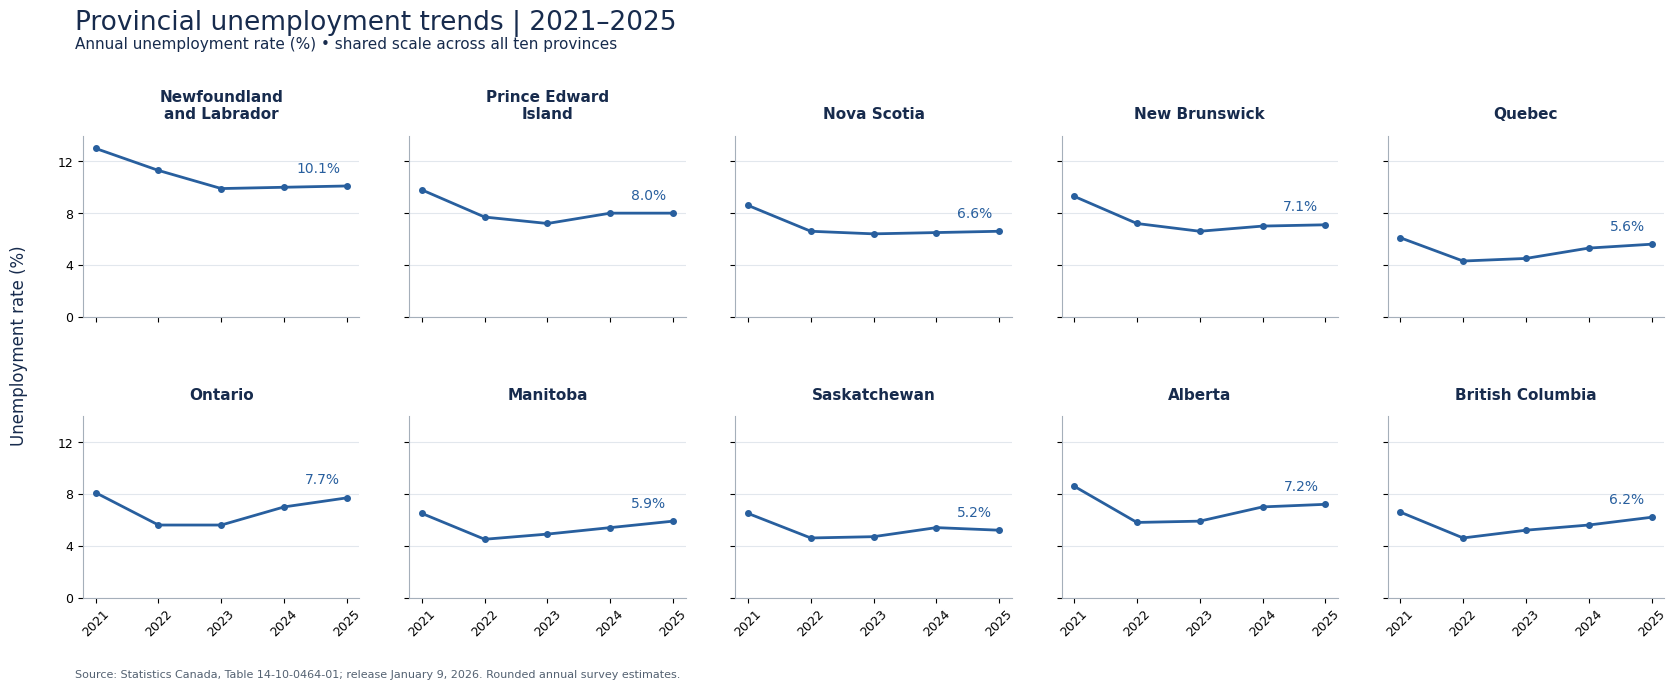

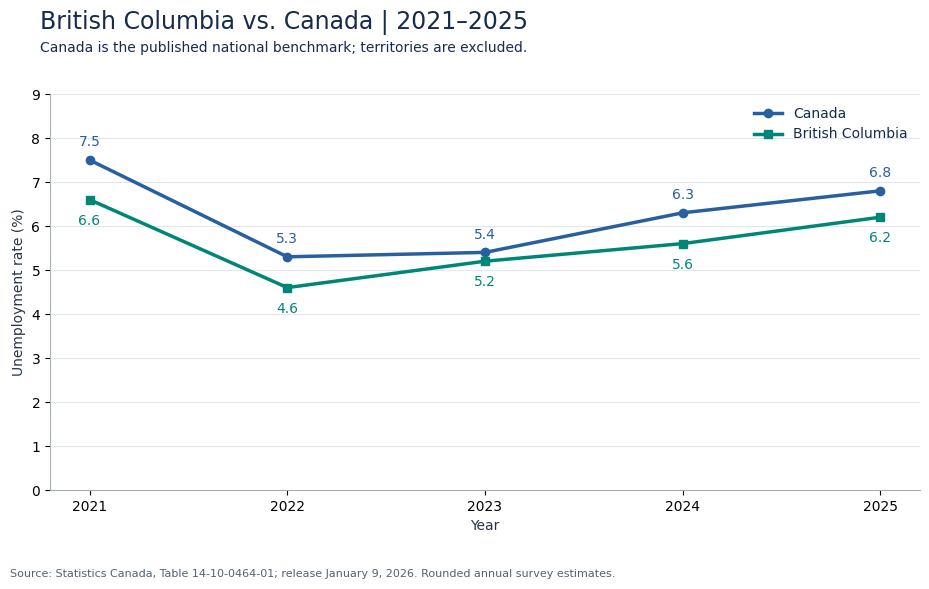

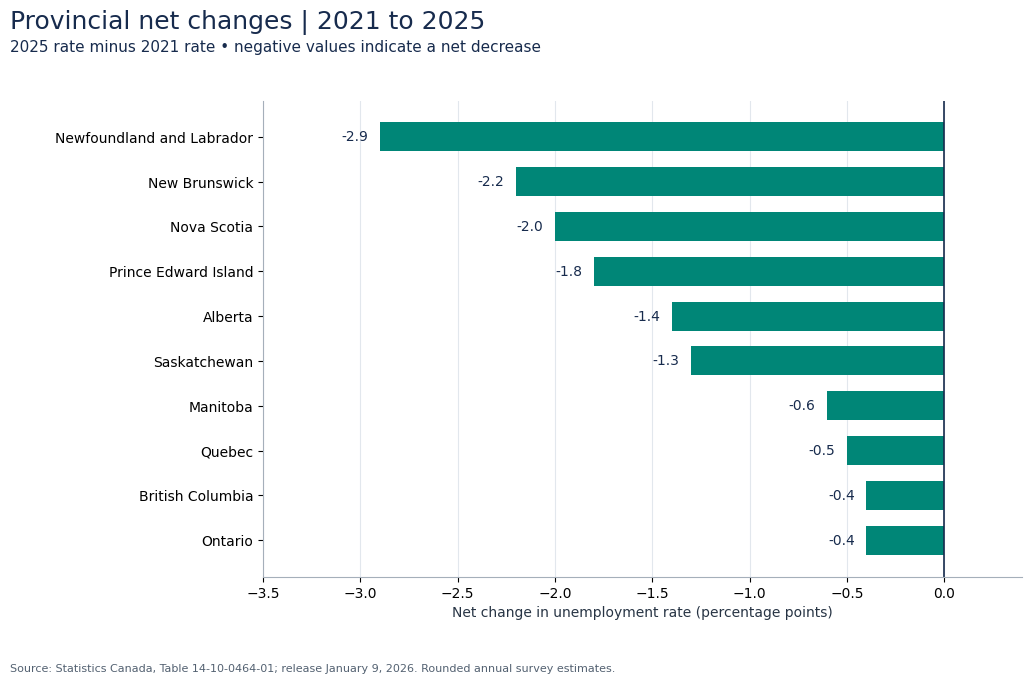

In [5]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.labelcolor': '#273444',
                     'text.color': '#172B4D', 'axes.edgecolor': '#A5AFBA',
                     'savefig.facecolor': 'white'})
SOURCE = 'Source: Statistics Canada, Table 14-10-0464-01; release January 9, 2026. Rounded annual survey estimates.'
BLUE, TEAL = '#285F9E', '#008677'

def finish(fig, name, source_y=0.025):
    fig.text(0.05, source_y, SOURCE, fontsize=8, color='#536171')
    fig.savefig(FIGURES / name, dpi=180)
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(2, 5, figsize=(17, 7), sharex=True, sharey=True)
for ax, province in zip(axes.flat, PROVINCES):
    values = rates.loc[province, YEARS]
    ax.plot(YEARS, values, color=BLUE, marker='o', linewidth=2, markersize=4)
    title = province.replace('Newfoundland and Labrador', 'Newfoundland\nand Labrador').replace('Prince Edward Island', 'Prince Edward\nIsland')
    ax.set_title(title, fontsize=11, pad=12)
    ax.set_ylim(0, 14)
    ax.set_yticks([0, 4, 8, 12])
    ax.set_xticks(YEARS, [str(y) for y in YEARS], rotation=45)
    ax.tick_params(axis='both', labelsize=9)
    ax.grid(axis='y', color='#E2E7ED')
    ax.annotate(f'{values.loc[2025]:.1f}%', (2025, values.loc[2025]), xytext=(-5, 10),
                textcoords='offset points', ha='right', fontsize=10, color=BLUE)
fig.suptitle('Provincial unemployment trends | 2021–2025', fontsize=19, x=0.05, ha='left', y=0.98)
fig.text(0.05, 0.925, 'Annual unemployment rate (%) • shared scale across all ten provinces', fontsize=11)
fig.supylabel('Unemployment rate (%)', x=0.012)
fig.subplots_adjust(left=0.055, right=0.985, top=0.80, bottom=0.14, hspace=0.55, wspace=0.18)
finish(fig, 'provincial_unemployment_trends.png')

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(bc['year'], bc['canada_rate'], color=BLUE, marker='o', linewidth=2.5, label='Canada')
ax.plot(bc['year'], bc['bc_rate'], color=TEAL, marker='s', linewidth=2.5, label='British Columbia')
for year, national, provincial in bc[['year', 'canada_rate', 'bc_rate']].itertuples(index=False, name=None):
    ax.annotate(f'{national:.1f}', (year, national), xytext=(0, 10), textcoords='offset points', ha='center', color=BLUE)
    ax.annotate(f'{provincial:.1f}', (year, provincial), xytext=(0, -18), textcoords='offset points', ha='center', color=TEAL)
ax.set_ylim(0, 9)
ax.set_xticks(YEARS)
ax.set_xlabel('Year')
ax.set_ylabel('Unemployment rate (%)')
ax.grid(axis='y', color='#E2E7ED')
ax.legend(loc='upper right', frameon=False)
fig.suptitle('British Columbia vs. Canada | 2021–2025', x=0.08, ha='left', fontsize=17, y=0.97)
fig.text(0.08, 0.90, 'Canada is the published national benchmark; territories are excluded.', fontsize=10)
fig.subplots_adjust(left=0.09, right=0.96, top=0.83, bottom=0.17)
finish(fig, 'bc_vs_canada_unemployment.png')

ordered = summary.sort_values(['net_change_pp', 'geography'])
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(ordered['geography'], ordered['net_change_pp'], color=TEAL, height=0.65)
ax.invert_yaxis()
ax.axvline(0, color='#172B4D', linewidth=1.2)
for i, value in enumerate(ordered['net_change_pp']):
    ax.text(value-0.06, i, f'{value:+.1f}', va='center', ha='right', fontsize=10)
ax.set_xlim(-3.5, 0.4)
ax.set_xlabel('Net change in unemployment rate (percentage points)')
ax.grid(axis='x', color='#E2E7ED')
ax.set_axisbelow(True)
fig.suptitle('Provincial net changes | 2021 to 2025', x=0.05, ha='left', fontsize=18, y=0.97)
fig.text(0.05, 0.91, '2025 rate minus 2021 rate • negative values indicate a net decrease', fontsize=11)
fig.subplots_adjust(left=0.28, right=0.97, top=0.84, bottom=0.16)
finish(fig, 'provincial_net_changes.png')


## Verified findings
The following reporting statements are generated from validated calculations rather than manually entered figures. Interpret the start-to-end change alongside the annual path.


In [6]:
largest_decline = summary.loc[summary['net_change_pp'].idxmin()]
smallest_change = summary['net_change_pp'].max()
smallest_names = ', '.join(summary.loc[summary['net_change_pp'].eq(smallest_change), 'geography'])
require(summary['net_change_pp'].lt(0).all(), 'Net-decrease narrative mismatch.')
require(bc['gap_pp'].lt(0).all(), 'BC benchmark narrative mismatch.')
findings = [
    f"All ten provinces had lower unemployment rates in 2025 than in 2021; net changes ranged from {summary['net_change_pp'].min():+.1f} to {summary['net_change_pp'].max():+.1f} percentage points. No province recorded a net increase.",
    f"{largest_decline['geography']} had the largest net decrease: {largest_decline['rate_2021']:.1f}% to {largest_decline['rate_2025']:.1f}% ({largest_decline['net_change_pp']:+.1f} pp).",
    f"{smallest_names} shared the smallest net decrease ({smallest_change:+.1f} pp each).",
    f"BC was below Canada in all five years. BC minus Canada ranged from {bc['gap_pp'].min():+.1f} to {bc['gap_pp'].max():+.1f} pp; the 2025 gap was {bc.loc[bc['year'].eq(2025), 'gap_pp'].iloc[0]:+.1f} pp.",
    f"Canada moved from {rates.loc['Canada', 2021]:.1f}% in 2021 to {rates.loc['Canada', 2025]:.1f}% in 2025 ({rates.loc['Canada', 2025]-rates.loc['Canada', 2021]:+.1f} pp)."
]
for statement in findings:
    print('•', statement)
print('Annual path:')
print('• Every province declined from 2021 to 2022; every province increased from 2023 to 2024.')
require(annual.loc[annual['geography'].isin(PROVINCES) & annual['year'].eq(2022), 'year_over_year_change_pp'].lt(0).all(),
        '2021–2022 narrative does not match data.')
require(annual.loc[annual['geography'].isin(PROVINCES) & annual['year'].eq(2024), 'year_over_year_change_pp'].gt(0).all(),
        '2023–2024 narrative does not match data.')
print('• In 2025, Saskatchewan had the lowest provincial rate (5.2%); Newfoundland and Labrador had the highest (10.1%).')
require(rates.loc[PROVINCES, 2025].idxmin() == 'Saskatchewan' and rates.loc[PROVINCES, 2025].min() == 5.2,
        'Lowest-rate narrative mismatch.')
require(rates.loc[PROVINCES, 2025].idxmax() == 'Newfoundland and Labrador' and rates.loc[PROVINCES, 2025].max() == 10.1,
        'Highest-rate narrative mismatch.')


• All ten provinces had lower unemployment rates in 2025 than in 2021; net changes ranged from -2.9 to -0.4 percentage points. No province recorded a net increase.
• Newfoundland and Labrador had the largest net decrease: 13.0% to 10.1% (-2.9 pp).
• British Columbia, Ontario shared the smallest net decrease (-0.4 pp each).
• BC was below Canada in all five years. BC minus Canada ranged from -0.9 to -0.2 pp; the 2025 gap was -0.6 pp.
• Canada moved from 7.5% in 2021 to 6.8% in 2025 (-0.7 pp).
Annual path:
• Every province declined from 2021 to 2022; every province increased from 2023 to 2024.
• In 2025, Saskatchewan had the lowest provincial rate (5.2%); Newfoundland and Labrador had the highest (10.1%).


## Limitations and further analysis
- These are rounded survey estimates. Differences inherit rounding; small differences should not be treated as precise population measurements.
- No confidence intervals or statistical significance tests were used. Rankings describe published point estimates only.
- Annual rates hide monthly variation and differences within provinces. Five years is a short reporting window, with 2021 as the fixed baseline.
- Unemployment rate is not a complete measure of labour-market health: participation, employment rate, hours, wages and population composition are not analysed here.
- No causal explanation, forecast, job-search outcome or operational business impact is established.
- The supplied export is a fixed source snapshot. Later published revisions may differ; the checksum protects reproducibility, not future freshness.
- This export does not expose separate status, vector or geographic-code fields. Scope selection is based on verified exact labels, with metadata and footnotes retained in the raw file.

**Recommended next steps:** add published employment and participation rates, examine monthly trends, and compare appropriate subgroups or regions using their own quality controls. Review confidence intervals before making inferential comparisons. Investigate mechanisms with additional evidence rather than attributing changes to a policy or event from these rates alone.

## Output verification
The final cell confirms every expected output exists and matches the in-memory analytical tables. Re-running regenerates outputs deterministically from the unchanged source.


In [7]:
clean_reload = pd.read_csv(PROCESSED / 'provincial_unemployment_2021_2025.csv')
pd.testing.assert_frame_equal(clean_reload, tidy)
pd.testing.assert_frame_equal(pd.read_csv(TABLES / 'provincial_summary.csv'), summary)
pd.testing.assert_frame_equal(pd.read_csv(TABLES / 'bc_canada_comparison.csv'), bc)
pd.testing.assert_frame_equal(pd.read_csv(TABLES / 'annual_changes.csv'), annual)
for filename in ['provincial_unemployment_trends.png', 'bc_vs_canada_unemployment.png', 'provincial_net_changes.png']:
    require((FIGURES / filename).is_file() and (FIGURES / filename).stat().st_size > 0,
            f'Missing or empty chart: {filename}')
require(hashlib.sha256(RAW.read_bytes()).hexdigest() == EXPECTED_SHA256, 'Raw file changed.')
print('PASS: saved tables agree with calculations; all three chart files exist; raw input unchanged.')


PASS: saved tables agree with calculations; all three chart files exist; raw input unchanged.
